In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [ ]:
CSV_PATH = "team_responses.xlsx"

df = pd.read_excel(CSV_PATH)

rename_map = {
    "Team member 1 contribution": "tm1",
    "Team member 2 contribution": "tm2",
    "Team member 3 contribution": "tm3",
    "Team member 4 contribution": "tm4",
    "Team member 5 contribution": "tm5",
    "Your own contribution": "own_contribution",
    "How often do you share memes or humorous content in the team chats?": "humor",
    "How successful do you believe your team is? 1-10": "success"
}

df = df.rename(columns=rename_map)

print(df.columns, "\n")


Index(['Timestamp',
       'Write each team member names (dictionary order based on roll number)',
       'tm1', 'tm2', 'tm3', 'tm4', 'tm5', 'own_contribution', 'humor',
       'success'],
      dtype='object') 



In [ ]:
needed_cols = ["tm1", "tm2", "tm3", "tm4", "tm5", "own_contribution", "humor", "success"]
existing_cols = [c for c in needed_cols if c in df.columns]
df = df[existing_cols]

print(df.head(), "\n")


Data (first 5 rows):
   tm1  tm2  tm3  tm4  tm5  own_contribution       humor  success
0    5    5  5.0  5.0  NaN               5.0  very often      9.0
1    5    5  5.0  5.0  NaN               5.0   sometimes      8.0
2    4    4  3.0  3.0  NaN               4.0      rarely      8.0
3    5    4  4.0  4.0  NaN               4.0  very often      7.0
4    5    5  5.0  5.0  5.0               5.0   sometimes      8.0 



In [6]:
contrib_cols = [c for c in ["tm1", "tm2", "tm3", "tm4", "tm5", "own_contribution"] if c in df.columns]
for c in contrib_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df["success"] = pd.to_numeric(df["success"], errors="coerce")

df = df.dropna(subset=["success"])
print(df.head(), "\n")

   tm1  tm2  tm3  tm4  tm5  own_contribution       humor  success
0    5    5  5.0  5.0  NaN               5.0  very often      9.0
1    5    5  5.0  5.0  NaN               5.0   sometimes      8.0
2    4    4  3.0  3.0  NaN               4.0      rarely      8.0
3    5    4  4.0  4.0  NaN               4.0  very often      7.0
4    5    5  5.0  5.0  5.0               5.0   sometimes      8.0 



In [8]:
humor_map = {
    "never": 0,
    "rarely": 1,
    "sometimes": 2,
    "often": 3,
    "very often": 4
}

def map_humor(v):
    if isinstance(v, str):
        return humor_map.get(v.strip().lower(), np.nan)
    return np.nan

df["humor_score"] = df["humor"].apply(map_humor)
df = df.dropna(subset=["humor_score"])
df["humor_score"] = df["humor_score"].astype(float)

print(df.head(), "\n")

   tm1  tm2  tm3  tm4  tm5  own_contribution       humor  success  humor_score
0    5    5  5.0  5.0  NaN               5.0  very often      9.0          4.0
1    5    5  5.0  5.0  NaN               5.0   sometimes      8.0          2.0
2    4    4  3.0  3.0  NaN               4.0      rarely      8.0          1.0
3    5    4  4.0  4.0  NaN               4.0  very often      7.0          4.0
4    5    5  5.0  5.0  5.0               5.0   sometimes      8.0          2.0 



In [83]:
df["avg_contribution"] = df[contrib_cols].mean(axis=1, skipna=True)

print(df[["avg_contribution", "humor_score", "success"]].head(), "\n")

SUCCESS_THRESHOLD = 9
df["success_label"] = (df["success"] >= SUCCESS_THRESHOLD).astype(int)

print("Success threshold:", SUCCESS_THRESHOLD)
print("Label counts:")
print(df["success_label"].value_counts(), "\n")

print("Sample labels:")
print(df[["success", "success_label"]].head(), "\n")

   avg_contribution  humor_score  success
0               5.0          4.0      9.0
1               5.0          2.0      8.0
2               3.6          1.0      8.0
3               4.2          4.0      7.0
4               5.0          2.0      8.0 

Success threshold: 9
Label counts:
success_label
0    33
1    28
Name: count, dtype: int64 

Sample labels:
   success  success_label
0      9.0              1
1      8.0              0
2      8.0              0
3      7.0              0
4      8.0              0 



In [84]:
feature_cols = ["avg_contribution", "humor_score"]
X = df[feature_cols].values
y = df["success_label"].values

test_size = 0.4 if len(df) > 5 else 0.5

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=test_size,
    random_state=42,
    stratify=y if len(np.unique(y)) > 1 and len(y) > 3 else None
)


In [86]:
log_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000,class_weight="balanced"))
])

log_pipeline.fit(X_train, y_train)
y_pred_log = log_pipeline.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_log))
print("Classification Report:\n", classification_report(y_test, y_pred_log, zero_division=0))

Accuracy: 0.68
Confusion Matrix:
 [[ 7  7]
 [ 1 10]]
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.50      0.64        14
           1       0.59      0.91      0.71        11

    accuracy                           0.68        25
   macro avg       0.73      0.70      0.68        25
weighted avg       0.75      0.68      0.67        25



In [87]:
rf_clf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced_subsample"
)

rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf, zero_division=0))

print("\nRandom Forest feature importances:")
for col, imp in zip(feature_cols, rf_clf.feature_importances_):
    print(f"  {col}: {imp:.3f}")

Accuracy: 0.68
Confusion Matrix:
 [[ 7  7]
 [ 1 10]]
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.50      0.64        14
           1       0.59      0.91      0.71        11

    accuracy                           0.68        25
   macro avg       0.73      0.70      0.68        25
weighted avg       0.75      0.68      0.67        25


Random Forest feature importances:
  avg_contribution: 0.717
  humor_score: 0.283


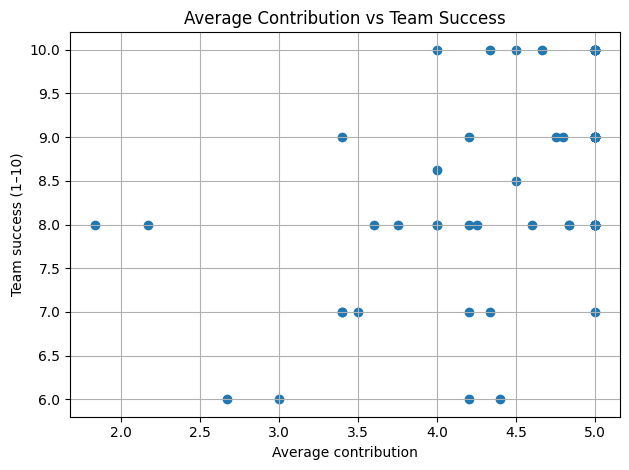

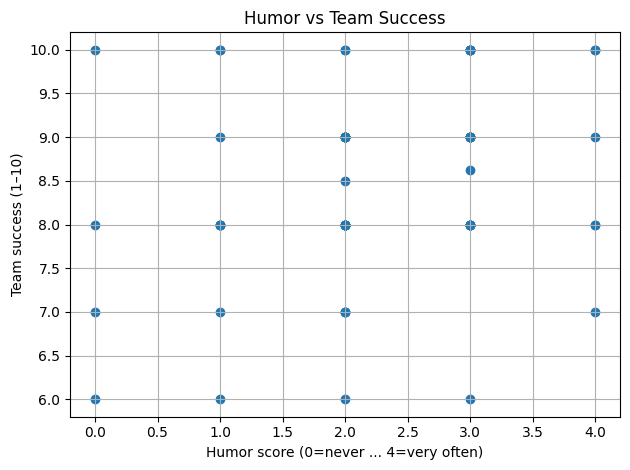

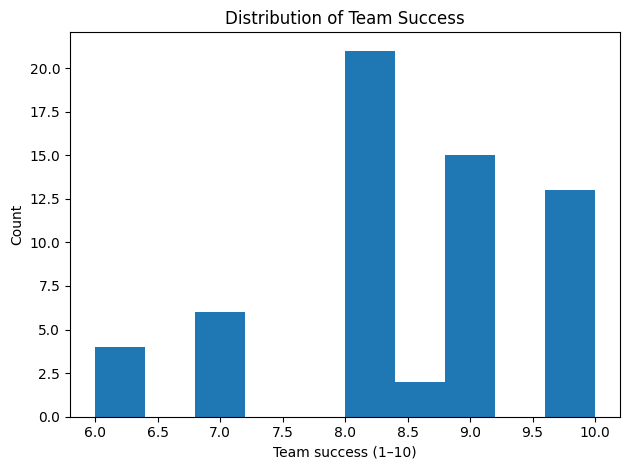

In [88]:

plt.figure()
plt.scatter(df["avg_contribution"], df["success"])
plt.xlabel("Average contribution")
plt.ylabel("Team success (1–10)")
plt.title("Average Contribution vs Team Success")
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure()
plt.scatter(df["humor_score"], df["success"])
plt.xlabel("Humor score (0=never ... 4=very often)")
plt.ylabel("Team success (1–10)")
plt.title("Humor vs Team Success")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure()
plt.hist(df["success"], bins=10)
plt.xlabel("Team success (1–10)")
plt.ylabel("Count")
plt.title("Distribution of Team Success")
plt.tight_layout()
plt.show()

C:\Users\kushj\AppData\Local\Temp\ipykernel_21316\3704272773.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


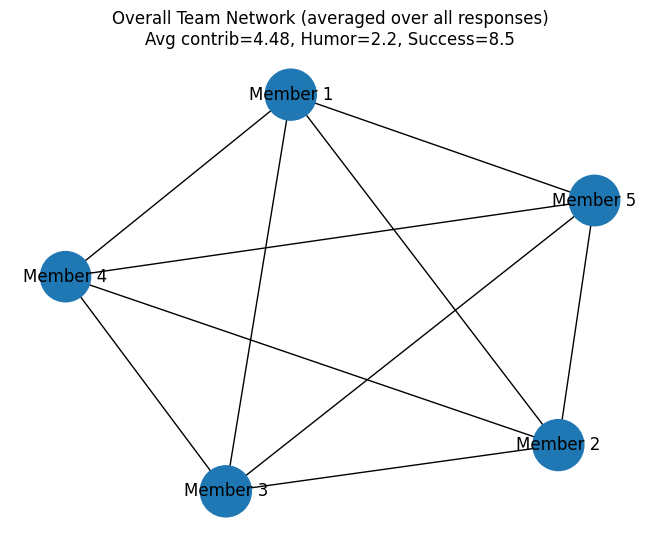

In [89]:
def draw_team_network(row, title_suffix=""):
    contribs = {
        "Member 1": row.get("tm1", np.nan),
        "Member 2": row.get("tm2", np.nan),
        "Member 3": row.get("tm3", np.nan),
        "Member 4": row.get("tm4", np.nan),
        "Member 5": row.get("tm5", np.nan),
    }

    contribs = {m: c for m, c in contribs.items() if pd.notna(c)}

    if len(contribs) == 0:
        return

    G = nx.Graph()
    for m in contribs.keys():
        G.add_node(m)

    members = list(contribs.keys())
    for i in range(len(members)):
        for j in range(i + 1, len(members)):
            G.add_edge(members[i], members[j])

    sizes = [contribs[m] * 300 for m in members]

    plt.figure()
    pos = nx.spring_layout(G, seed=42)
    nx.draw(G, pos, with_labels=True, node_size=sizes)
    plt.title(
        f"Overall Team Network {title_suffix}\n"
        f"Avg contrib={row['avg_contribution']:.2f}, "
        f"Humor={row['humor_score']:.1f}, "
        f"Success={row['success']:.1f}"
    )
    plt.tight_layout()
    plt.show()


overall_row = df.mean(numeric_only=True)
draw_team_network(overall_row, "(averaged over all responses)")


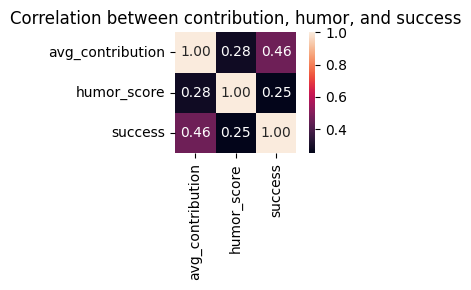

In [90]:
corr_cols = ["avg_contribution", "humor_score", "success"]
corr = df[corr_cols].corr()

plt.figure(figsize=(4, 3))
sns.heatmap(corr, annot=True, fmt=".2f", square=True)
plt.title("Correlation between contribution, humor, and success")
plt.tight_layout()
plt.show()


In [91]:
print(df[["avg_contribution", "humor_score", "success"]].describe(), "\n")

print("Average success by humor level:")
print(df.groupby("humor_score")["success"].mean(), "\n")

print("Average success by high/low success_label:")
print(df.groupby("success_label")[["avg_contribution", "humor_score"]].mean(), "\n")


       avg_contribution  humor_score    success
count         61.000000    61.000000  61.000000
mean           4.480601     2.245902   8.460984
std            0.750519     1.043324   1.130424
min            1.833333     0.000000   6.000000
25%            4.200000     2.000000   8.000000
50%            5.000000     2.000000   8.000000
75%            5.000000     3.000000   9.000000
max            5.000000     4.000000  10.000000 

Average success by humor level:
humor_score
0.0    7.750000
1.0    8.222222
2.0    8.295455
3.0    8.831000
4.0    8.666667
Name: success, dtype: float64 

Average success by high/low success_label:
               avg_contribution  humor_score
success_label                               
0                      4.202020     2.060606
1                      4.808929     2.464286 



In [92]:
def predict_team_success_from_inputs(tm1=None, tm2=None, tm3=None, tm4=None, tm5=None,
                                     own_contribution=None, humor_text="sometimes"):
    contrib_values = [v for v in [tm1, tm2, tm3, tm4, tm5, own_contribution] if v is not None]
    if len(contrib_values) == 0:
        raise ValueError("At least one contribution value must be provided.")

    avg_contribution = float(np.mean(contrib_values))

    humor_score = map_humor(humor_text)
    if np.isnan(humor_score):
        raise ValueError(f"Could not map humor text '{humor_text}' to a score.")

    x = np.array([[avg_contribution, humor_score]])
    prob_high = float(rf_clf.predict_proba(x)[0][1])
    label = int(rf_clf.predict(x)[0])

    return {
        "avg_contribution": avg_contribution,
        "humor_score": float(humor_score),
        "predicted_label": label,
        "prob_high_success": prob_high
    }


In [93]:
result = predict_team_success_from_inputs(
    tm1=1,
    tm2=1,
    tm3=1,
    tm4=1,
    tm5=1,
    own_contribution=1,
    humor_text="rarely"
)

print("Average contribution:", result["avg_contribution"])
print("Humor score:", result["humor_score"])
print("Predicted label (1=success, 0= might fail):", result["predicted_label"])
print("Probability success:", result["prob_high_success"])


Average contribution: 1.0
Humor score: 1.0
Predicted label (1=success, 0= might fail): 0
Probability success: 0.01820754716981132
